> **Review status:** Task 2/3 source and analysis fixes added on 2026-10-20. Revised cells have no saved results until rerun in the authenticated environment. Earlier validation outputs are historical, not results of this revision. Use `industry_failure_rates` as the sole prior table. See `data/TASK_2_3_REVIEW.md`.


# Challenge 3—Charge-off validation

### Does our idea of "fragile" match the businesses that actually failed?

Every edge-weight, every cascade and every fragility claim in this challenge is a **model**.
There is exactly one place in the whole dataset where the outcome is **real**: the SBA's loan
records say which small-business loans were **charged off**—the lender wrote the debt off, which is not proof of storefront closure. This notebook uses that ground truth three ways:

1. **Validate.** Do the industry structures our graph is built from—how much a business depends
   on purchased local inputs, how concentrated those inputs are, whether it lives on footfall,
   how much of a supply hub it is—predict which businesses failed? We train on California
   *outside* San Francisco and test *inside* San Francisco, so the test is out-of-area.
2. **Calibrate.** Turn the real failure history into a industry loan charge-off prior for every
   business in your corridor, with honest uncertainty. The graph tells you the **consequence**
   of a closure; this tells you its **likelihood**. A grant decision needs both.
3. **Ground-truth the corridor.** Re-match the corridor against *every* SBA loan since FY2010
   (the load notebook only used FY2020 onward), check each match by street address, and show
   what the businesses that really failed looked like to our model.

## What you will have when it finishes

| Table (in `a4i_econ`) | What it is | How real |
|---|---|---|
| `sba_loans_ca` | California SBA 7(a) loans to incorporated businesses, FY2010 on—no names, no street addresses | **real** |
| `industry_failure_rates` | Probability a business in each industry charges off within the horizon, shrunk toward its sector so small industries do not produce wild rates | **real outcomes**, smoothing is ours |
| `business_fragility` | One row per corridor business: failure probability, downstream reach from a GQL traversal, expected businesses exposed, a quadrant label | industry loan prior estimated; business exposure modeled |
| `corridor_loan_outcomes` | Every SBA loan we can match to a corridor business, with an address check | **real**, the match is ours |
| `validation_summary` | The headline numbers below, as rows the agent can quote | — |

## Before you run it

* Run `c3_01_load_explore.ipynb` (or `bash scripts/load.sh <corridor>`) first. This notebook reads
  the tables that one made.
* It uses the same graph-capable reservation as Section 1b of the load notebook. If that cell was
  never run in this project, the traversal cell will tell you.
* **Budget roughly 10 minutes**, most of it downloading two SBA files (a few hundred megabytes).
  The California subset is cached to BigQuery, so a second run takes about a minute.

**Read the prose between cells.** The interpretation is printed for you, but the caveats are in
the markdown, and the caveats are what a judge will ask about.

# 1. Setup

In [4]:
# --- Configuration -------------------------------------------------------------

DATASET  = "a4i_econ"
LOCATION = "US"

# The team's property graph. If it does not exist yet, Section 8 creates it using the exact DDL
# from Section 13 of the load notebook. If it DOES exist, it is used as-is and never replaced.
GRAPH = f"{DATASET}.LocalEconomy"

# The SBA renames these files every quarter (the _asof_ suffix). If a download 404s, open
# https://data.sba.gov/dataset/7a-504-foia, copy the current 7(a) links, paste them here.
SBA_FILES = {
    "FY2010-FY2019":  "https://data.sba.gov/sites/default/files/uploaded_resources/"
                      "FOIA_7a_FY2010_FY2019_asof_260630.csv",
    "FY2020-Present": "https://data.sba.gov/sites/default/files/uploaded_resources/"
                      "FOIA_7a_FY2020_Present_asof_260630.csv",
}
STATE         = "CA"
SF_ZIP_PREFIX = "941"     # San Francisco's ZIP codes. The test set is these loans.

# THE OUTCOME: did the loan charge off within this many months of approval?
# A fixed window is what makes old and new loans comparable - see Section 3. 48 months keeps
# cohorts FY2010-FY2022. Section 3 prints what 24, 36 and 60 would have said.
HORIZON_MONTHS = 48

# THE ASSUMPTION. Nothing in any dataset says what a grant does. We assume it cuts a business's
# chance of failing by this fraction (0.25 = a quarter). It only scales one column in Section 9,
# and Section 9 prints how the ranking moves if you are wrong about it. Say it out loud in the demo.
GRANT_RELATIVE_RISK_REDUCTION = 0.25

# The same constants the edge generator in the load notebook uses (its Sections 7 and 8), so the
# structure we test here is the structure your graph actually has. Change them there, change them here.
SUPPLY_COEFF_FLOOR    = 0.005
GENERIC_SUPPLIER_PCTL = 0.90
CONSUMER_PREFIXES     = ("44", "45", "72", "81", "71")

REFRESH_SBA = False       # True forces a re-download even when the cache table exists

REPO_RAW = ("https://raw.githubusercontent.com/haggman/"
            "A4I2026-challenge-3-micro-grants/main/")

# --- Imports and clients --------------------------------------------------------
import os, re, time, math, warnings
import numpy as np
import pandas as pd
import google.auth
from google.cloud import bigquery
from google.api_core.exceptions import NotFound

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

credentials, PROJECT_ID = google.auth.default()
PROJECT_ID = PROJECT_ID or os.environ.get("GOOGLE_CLOUD_PROJECT")
if not PROJECT_ID:
    raise RuntimeError("Could not determine your project. Set PROJECT_ID = 'your-project-id' by hand.")

client = bigquery.Client(project=PROJECT_ID)
DS = f"{PROJECT_ID}.{DATASET}"

# Ensure the BigQuery dataset exists so caching in Sections 2 and 8 succeeds
_ds_ref = bigquery.Dataset(DS)
_ds_ref.location = LOCATION
client.create_dataset(_ds_ref, exists_ok=True)

NOTEBOOK_START = time.time()
STEP_TIMES = {}
class step:
    def __init__(self, name): self.name = name
    def __enter__(self): self.t0 = time.time(); return self
    def __exit__(self, *exc):
        STEP_TIMES[self.name] = time.time() - self.t0
        print(f"\n[{self.name}] took {STEP_TIMES[self.name]:.1f}s")
        return False

def bq(sql):
    return client.query(sql).to_dataframe()

def table_exists(name):
    try:
        client.get_table(f"{DS}.{name}")
        return True
    except NotFound:
        return False

def load_table(df, name, description):
    """Replace a table and stamp its provenance on it, the way the load notebook does."""
    ref = f"{DS}.{name}"
    out = df.copy()
    for c in out.columns:                       # pyarrow will not load pandas categoricals
        if isinstance(out[c].dtype, pd.CategoricalDtype):
            out[c] = out[c].astype(str)
    client.load_table_from_dataframe(
        out, ref, job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE")).result()
    t = client.get_table(ref)
    t.description = description
    client.update_table(t, ["description"])
    print(f"  wrote {name:<24} {len(out):>8,} rows")

# Every headline number lands in here. Section 11 prints it as a block for the story lane and
# writes it to BigQuery for the agent.
RESULTS = {}
def result(key, value, detail=""):
    RESULTS[key] = (value, detail)

# --- What the load notebook left us ----------------------------------------------
needed   = ["businesses", "supplies"]
optional = ["borrowed_from", "draws_footfall_from", "employer_blocks", "tract_demographics"]
missing = [t for t in needed if not table_exists(t)]
if missing:
    print(f"WARNING: {missing} not found in {DS}.\n"
          f"Run c3_01_load_explore.ipynb (or bash scripts/load.sh) first before running Section 9+.")
HAVE = {t: table_exists(t) for t in needed + optional}

try:
    CORRIDOR = str(bq(f"SELECT ANY_VALUE(corridor) AS c FROM `{DS}.businesses`").c.iloc[0])
except Exception:                                                       # noqa: BLE001
    CORRIDOR = "(corridor column not found)"
print(f"Project  : {PROJECT_ID}")
print(f"Dataset  : {DS}")
print(f"Corridor : {CORRIDOR}")
print(f"Tables   : " + ", ".join(f"{t}{'' if ok else ' (absent)'}" for t, ok in HAVE.items()))

Run c3_01_load_explore.ipynb (or bash scripts/load.sh) first before running Section 9+.
Project  : qwiklabs-gcp-04-486b161c6a8e
Dataset  : qwiklabs-gcp-04-486b161c6a8e.a4i_econ
Corridor : (corridor column not found)
Tables   : businesses (absent), supplies (absent), borrowed_from (absent), draws_footfall_from (absent), employer_blocks (absent), tract_demographics (absent)


# 2. Load the real outcomes

## Why two files, and why the whole state

The load notebook pulled one SBA file, FY2020 onward, and matched it to your corridor. That gives
you a handful of loans at most, and loans that are so young most of them have not had time to
fail. **A handful of loans cannot validate anything.** So we widen in two directions:

* **Back in time.** The FY2010–FY2019 file has loans whose story is over—they were repaid or they
  were charged off. Those are the outcomes worth learning from.
* **Out in space.** All of California, not one corridor. Tens of thousands of loans instead of a
  handful. We still keep San Francisco separate, because it is the test set.

## Two filters, both deliberate

**Incorporated borrowers only.** `BusinessType = Individual` is a sole proprietor, and the load
notebook already drops those for privacy. Dropping them here too keeps the population we learn
from the same as the population in your graph, which only contains incorporated businesses.

**No names or street addresses are written anywhere.** We need them in memory for one thing—
matching San Francisco loans to your corridor in Section 9, with an address check. The table we
cache to BigQuery has neither.

In [5]:
SBA_WANT = ["BorrName", "BorrStreet", "BorrCity", "BorrState", "BorrZip",
            "BankName", "GrossApproval", "ApprovalDate", "TermInMonths",
            "NaicsCode", "FranchiseCode", "FranchiseName", "BusinessType", "BusinessAge",
            "LoanStatus", "ChargeOffDate", "GrossChargeOffAmount", "JobsSupported"]
# Columns that would be valuable if a future file carries them. We report them, we do not need them.
SBA_INTERESTING = re.compile(r"delinq|purchase|liquid|default", re.IGNORECASE)

# Every SBA file name carries its as-of date. That date is the end of our observation window.
_asof = {re.search(r"asof_(\d{6})", u).group(1) for u in SBA_FILES.values()
         if re.search(r"asof_(\d{6})", u)}
if len(_asof) != 1:
    raise ValueError(f"The SBA files disagree about their as-of date ({_asof}). Use one quarter's files.")
SBA_ASOF = pd.Timestamp(f"20{next(iter(_asof))[:2]}-{next(iter(_asof))[2:4]}-{next(iter(_asof))[4:]}")

def digits(s, n=None):
    s = s.astype("string").str.replace(r"\.0+$", "", regex=True).str.extract(r"(\d+)")[0]
    return s.str[:n] if n else s

def num(s):
    return pd.to_numeric(s.astype("string").str.replace(r"[$,\s]", "", regex=True), errors="coerce")

def parse_date(s):
    s = s.astype("string").str.strip()
    out = pd.to_datetime(s, format="%m/%d/%Y", errors="coerce")
    retry = out.isna() & s.notna() & (s != "")
    if retry.any():
        try:
            out[retry] = pd.to_datetime(s[retry], errors="coerce", format="mixed")
        except (TypeError, ValueError):
            out[retry] = pd.to_datetime(s[retry], errors="coerce")
    return out

def read_sba(label, url):
    keep, seen_cols = [], None
    reader = pd.read_csv(url, chunksize=200_000, dtype=str, encoding="latin-1",
                         on_bad_lines="skip", usecols=lambda c: c in SBA_WANT or bool(SBA_INTERESTING.search(c)))
    for i, chunk in enumerate(reader):
        if i == 0:
            seen_cols = list(chunk.columns)
            gone = [c for c in SBA_WANT if c not in chunk.columns]
            extra = [c for c in chunk.columns if c not in SBA_WANT]
            print(f"  {label}: {len(seen_cols)} wanted columns present"
                  + (f"; MISSING {gone}" if gone else ""))
            if extra:
                print(f"  {label}: also carries {extra} - worth a look, not used here")
        keep.append(chunk[chunk["BorrState"].astype("string").str.strip().str.upper() == STATE])
    df = pd.concat(keep, ignore_index=True)
    df["source_file"] = label
    print(f"  {label}: {len(df):,} {STATE} loans")
    return df

def tidy_loans(raw):
    """One clean row per loan. Names and streets are kept ONLY in the in-memory SF frame."""
    status = raw.LoanStatus.astype("string").str.upper().str.replace(r"\s+", "", regex=True)
    fr_name = raw.get("FranchiseName", pd.Series(pd.NA, index=raw.index)).astype("string").str.strip()
    fr_code = digits(raw.get("FranchiseCode", pd.Series(pd.NA, index=raw.index)))
    age = raw.get("BusinessAge", pd.Series(pd.NA, index=raw.index)).astype("string").str.lower()
    approval = parse_date(raw.ApprovalDate)
    return pd.DataFrame({
        "source_file":      raw.source_file.values,
        "status":           status.values,
        "approval_date":    approval.values,
        "approval_fy":      (approval.dt.year + (approval.dt.month >= 10).astype("Int64")).values,
        "chargeoff_date":   parse_date(raw.ChargeOffDate).values,
        "gross_approval":   num(raw.GrossApproval).values,
        "chargeoff_amount": num(raw.GrossChargeOffAmount).values,
        "term_months":      num(raw.TermInMonths).values,
        "jobs_supported":   num(raw.get("JobsSupported", pd.Series(pd.NA, index=raw.index))).values,
        "naics":            digits(raw.NaicsCode, 6).values,
        "franchised":       ((fr_name.fillna("") != "") | (fr_code.fillna("0").str.strip("0") != "")).values,
        "business_age":     np.select(
            [age.str.contains("startup", na=False), age.str.contains("new", na=False),
             age.str.contains("change of ownership", na=False), age.str.contains("existing", na=False)],
            ["startup", "new (2 years or less)", "change of ownership", "existing (over 2 years)"],
            default="unanswered"),
        "zip5":             digits(raw.BorrZip, 5).values,
        "bank_name":        raw.BankName.astype("string").str.strip().values,
    })

sba_sf_named = None          # in-memory only: SF loans WITH names, for Section 9's match
if table_exists("sba_loans_ca") and not REFRESH_SBA:
    with step("read cached California loans"):
        loans = bq(f"SELECT * FROM `{DS}.sba_loans_ca`")
        loans["approval_date"]  = pd.to_datetime(loans.approval_date)
        loans["chargeoff_date"] = pd.to_datetime(loans.chargeoff_date)
    print(f"Read {len(loans):,} loans from the cache. Set REFRESH_SBA = True to re-download.")
    print("Note: the corridor re-match in Section 9 needs names, which the cache deliberately does")
    print("not hold - it will reuse corridor_loan_outcomes from the first run instead.")
else:
    with step("download SBA 7(a) files"):
        frames = []
        for label, url in SBA_FILES.items():
            try:
                frames.append(read_sba(label, url))
            except Exception as exc:                                   # noqa: BLE001
                print(f"  COULD NOT READ {label}: {exc}")
                if "404" in str(exc):
                    print("  A 404 means the SBA rotated its quarterly file names. Copy the current")
                    print("  7(a) links from https://data.sba.gov/dataset/7a-504-foia into SBA_FILES.")
        if not frames:
            raise RuntimeError("No SBA file could be read, so there is no ground truth to validate against.")
        raw_sba = pd.concat(frames, ignore_index=True)

    before = len(raw_sba)
    if "BusinessType" in raw_sba.columns:
        raw_sba = raw_sba[raw_sba.BusinessType.astype("string").str.strip().str.lower() != "individual"]
        raw_sba = raw_sba.reset_index(drop=True)
        print(f"\nDropped individual (sole proprietor) borrowers: {before - len(raw_sba):,}")
    else:
        print("\nWARNING - no BusinessType column, so sole proprietors could not be dropped. Tell a coach.")

    loans = tidy_loans(raw_sba)
    is_sf = loans.zip5.fillna("").str.startswith(SF_ZIP_PREFIX).values
    sba_sf_named = raw_sba[is_sf].assign(
        _status=loans.status[is_sf].values, _approval=loans.approval_date[is_sf].values,
        _chargeoff=loans.chargeoff_date[is_sf].values, _naics=loans.naics[is_sf].values)
    del raw_sba

    with step("cache California loans to BigQuery"):
        load_table(loans, "sba_loans_ca",
                   f"REAL. SBA 7(a) FOIA loans (as of {SBA_ASOF:%Y-%m-%d}) to incorporated {STATE} "
                   f"borrowers. No borrower names or street addresses. Source: data.sba.gov, U.S. Government Works.")

print(f"\nCalifornia loans to incorporated businesses : {len(loans):,}")
print(f"  of which San Francisco (ZIP {SF_ZIP_PREFIX}xx)       : {loans.zip5.fillna('').str.startswith(SF_ZIP_PREFIX).sum():,}")
print(f"  approved FY{int(loans.approval_fy.min())}-FY{int(loans.approval_fy.max())}, observed to {SBA_ASOF:%Y-%m-%d}")
print("\nLoan status as published:")
print(loans.status.value_counts(dropna=False).to_string())

  FY2010-FY2019: 18 wanted columns present
  FY2010-FY2019: 68,070 CA loans
  FY2020-Present: 18 wanted columns present
  FY2020-Present: 45,200 CA loans

[download SBA 7(a) files] took 10.6s

Dropped individual (sole proprietor) borrowers: 18,698
  wrote sba_loans_ca               94,572 rows

[cache California loans to BigQuery] took 4.2s

California loans to incorporated businesses : 94,572
  of which San Francisco (ZIP 941xx)       : 2,222
  approved FY2010-FY2026, observed to 2026-06-30

Loan status as published:
status
PIF       45112
EXEMPT    31469
CANCLD    12252
CHGOFF     3810
COMMIT     1929


# 3. Define "failed" so that old and new loans are comparable

## The trap

A loan approved in 2012 has had fourteen years to fail. A loan approved in 2024 has had two.
Count "ever charged off" and the 2024 loans look safe purely because they are young. Every
industry that borrowed recently would look healthier than it is. This is called **censoring**,
and it is the most common way a validation on loan data quietly lies.

## The fix: a fixed window

A loan counts as **failed** if it charged off within `HORIZON_MONTHS` of approval. A loan is only
**eligible** if we have watched it for that long. Every loan in the analysis then had exactly the
same chance to fail. We lose the most recent cohorts, and that is the price of a fair comparison.

## Statuses we drop

* `CANCLD`—cancelled. The money never went out, so the loan could not fail.
* `COMMIT`—approved, not yet disbursed. Same reason.

`PIF` (paid in full) and `EXEMPT` (disbursed and still open—the SBA withholds the detail, but
it is neither paid off nor charged off) both mean "did not charge off". `CHGOFF` is the event.
The status table printed above should show exactly these five; if it shows anything else, check
the data dictionary on the SBA page before trusting the rates.

In [6]:
def failure_frame(df, horizon):
    d = df[~df.status.isin(["CANCLD", "COMMIT"])].copy()
    d = d[d.approval_date.notna() & (d.approval_date <= SBA_ASOF - pd.DateOffset(months=horizon))]
    chg = d.status.eq("CHGOFF")
    months = (d.chargeoff_date - d.approval_date).dt.days / 30.4375
    # A CHGOFF with no date: we cannot place it in time, so we count it as a failure (conservative
    # for the base rate) and report how many there were.
    d["failed"] = (chg & (months.isna() | (months <= horizon))).astype(int)
    d["months_to_chargeoff"] = months.where(chg)
    return d

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half, centre + half)

elig = failure_frame(loans, HORIZON_MONTHS)
elig["sf"] = elig.zip5.fillna("").str.startswith(SF_ZIP_PREFIX)
undated = int((elig.status.eq("CHGOFF") & elig.chargeoff_date.isna()).sum())

n, k = len(elig), int(elig.failed.sum())
lo, hi = wilson(k, n)
sf = elig[elig.sf]
print(f"Eligible loans (watched at least {HORIZON_MONTHS} months): {n:,}")
print(f"  approved FY{int(elig.approval_fy.min())}-FY{int(elig.approval_fy.max())}")
print(f"Failed within {HORIZON_MONTHS} months : {k:,}  = {k / n:.2%}  (95% CI {lo:.2%}-{hi:.2%})")
print(f"  San Francisco only      : {int(sf.failed.sum()):,} of {len(sf):,} = {sf.failed.mean():.2%}")
print(f"  charge-offs with no date: {undated} (counted as failures)")
result("base_rate", f"{k / n:.2%}",
       f"{k:,} of {n:,} CA SBA 7(a) loans to incorporated businesses charged off within "
       f"{HORIZON_MONTHS} months (FY{int(elig.approval_fy.min())}-FY{int(elig.approval_fy.max())})")
result("base_rate_sf", f"{sf.failed.mean():.2%}", f"{int(sf.failed.sum())} of {len(sf):,} San Francisco loans")

print("\nBy approval year. Watch FY2020-FY2021: pandemic-era loans were made, and failed, for")
print("reasons that have nothing to do with a corridor's structure. The models control for year.")
cohort = (elig.groupby("approval_fy")
              .agg(loans=("failed", "size"), failed=("failed", "sum"))
              .assign(rate=lambda t: (t.failed / t.loans).map("{:.1%}".format)))
print(cohort.to_string())

print(f"\nHow much the window matters (same data, different horizon):")
for h in (24, 36, 48, 60):
    e = failure_frame(loans, h)
    if len(e):
        print(f"  {h:>2} months: {e.failed.mean():6.2%} of {len(e):>7,} loans "
              f"(cohorts to FY{int(e.approval_fy.max())})")

Eligible loans (watched at least 48 months): 58,647
  approved FY2010-FY2022
Failed within 48 months : 1,570  = 2.68%  (95% CI 2.55%-2.81%)
  San Francisco only      : 34 of 1,490 = 2.28%
  charge-offs with no date: 0 (counted as failures)

By approval year. Watch FY2020-FY2021: pandemic-era loans were made, and failed, for
reasons that have nothing to do with a corridor's structure. The models control for year.
             loans  failed  rate
approval_fy                     
2010          3141     127  4.0%
2011          3879      87  2.2%
2012          3691      81  2.2%
2013          4078      65  1.6%
2014          4898     106  2.2%
2015          6019     165  2.7%
2016          6071     204  3.4%
2017          5784     176  3.0%
2018          5450     190  3.5%
2019          4697     152  3.2%
2020          3820      62  1.6%
2021          4490      67  1.5%
2022          2629      88  3.3%

How much the window matters (same data, different horizon):
  24 months:  0.83% of  69,0

# 4. Measure each industry the way the graph sees it

Your supply edges come from one file: `data/bea_direct_requirements.csv`, the federal statistic
for how many cents of input each industry buys from each other industry per dollar of output.
Whatever the graph "knows" about a business's dependencies, it learned here. So these are the
structural claims worth testing against real failures:

| Feature | What it says | Why it might predict failure |
|---|---|---|
| `local_input_intensity` | Cents per dollar of output bought from the kinds of local supplier the graph links (above the coefficient floor, ubiquitous inputs removed) | Lose a supplier, lose margin |
| `input_hhi` | How concentrated those inputs are (Herfindahl, 0–1) | One critical input is a single point of failure |
| `downstream_reach` | How many industries buy from this one—**how much of a hub it is** | The hub question: are the businesses everybody depends on also the ones likely to fail? |
| `consumer_facing` | Retail, food service, personal services, arts—the industries the footfall edges point at | Depends on people walking past |

## One thing in the BEA file you should know about

The file is keyed by four-digit NAICS, but BEA publishes at a coarser level, so one BEA
industry is copied onto every NAICS code it covers. "Food manufacturing" becomes eleven rows
with the same coefficient. Sum the rows and you count restaurants' food inputs eleven times. We
collapse back to BEA industries before measuring anything. The same duplication affects the edge
generator—a restaurant can draw supply edges from any food manufacturer at the full coefficient—
which is worth knowing if your team improves that generator.

In [7]:
with step("load BEA structure"):
    bea  = pd.read_csv(REPO_RAW + "data/bea_direct_requirements.csv", dtype=str)
    conc = pd.read_csv(REPO_RAW + "data/bea_naics_concordance.csv", dtype=str)
bea["coefficient"] = pd.to_numeric(bea.coefficient, errors="coerce")
bea = bea[bea.coefficient > 0]

# NAICS key -> BEA industry. One key (531, real estate) maps to two BEA codes; we keep the first
# and say so, because it touches almost no storefront business.
N2B = conc.drop_duplicates("naics4").set_index("naics4").bea_code.to_dict()

def to_bea(code):
    code = re.sub(r"\D", "", str(code))
    for n in (6, 5, 4, 3, 2):
        if len(code) >= n and code[:n] in N2B:
            return N2B[code[:n]]
    return None

# Generic suppliers, exactly as the edge generator defines them: industries in the top decile by
# how many industries they sell to (accounting, legal, advertising...). Substitutable inputs.
_pairs = bea[bea.coefficient >= SUPPLY_COEFF_FLOOR]
_reach = _pairs.groupby("supplier_naics4").buyer_naics4.nunique()
GENERIC_KEYS = set(_reach[_reach > _reach.quantile(GENERIC_SUPPLIER_PCTL)].index)
GENERIC_BEA = {N2B.get(k) for k in GENERIC_KEYS} - {None}

ind = bea.assign(buyer=bea.buyer_naics4.map(N2B), supplier=bea.supplier_naics4.map(N2B)).dropna(
    subset=["buyer", "supplier"])
spread = ind.groupby(["buyer", "supplier"]).coefficient.agg(["min", "max"])
print(f"Collapsed {len(bea):,} NAICS-keyed rows to {len(spread):,} BEA industry pairs "
      f"(largest disagreement inside a pair: {(spread['max'] - spread['min']).max():.2e})")
ind = ind.groupby(["buyer", "supplier"], as_index=False).coefficient.max()

local = ind[(ind.coefficient >= SUPPLY_COEFF_FLOOR) & ~ind.supplier.isin(GENERIC_BEA)
            & (ind.buyer != ind.supplier)]
def _hhi(c):
    s = c / c.sum()
    return float((s * s).sum())

STRUCT = pd.DataFrame({
    "local_input_intensity": local.groupby("buyer").coefficient.sum(),
    "n_critical_inputs":     local.groupby("buyer").supplier.nunique(),
    "input_hhi":             local.groupby("buyer").coefficient.apply(_hhi),
    "downstream_reach":      ind[ind.coefficient >= SUPPLY_COEFF_FLOOR].groupby("supplier").buyer.nunique(),
}).fillna({"local_input_intensity": 0.0, "n_critical_inputs": 0, "downstream_reach": 0})
STRUCT.index.name = "bea_code"
STRUCT_FEATURES = ["local_input_intensity", "input_hhi", "downstream_reach", "consumer_facing"]

def add_structure(df, naics_col="naics"):
    d = df.copy()
    d["bea_code"] = d[naics_col].map(to_bea)
    d = d.join(STRUCT, on="bea_code")
    d["consumer_facing"] = d[naics_col].astype("string").str[:2].isin(CONSUMER_PREFIXES).astype(int)
    return d

elig = add_structure(elig)
cover = elig.bea_code.notna().mean()
print(f"Loans whose industry maps to a BEA industry: {cover:.1%}")
print(f"Ubiquitous supplier industries excluded (as in the edge generator): {sorted(GENERIC_BEA)}")
print("\nWhat a few familiar industries look like to the graph:")
_show = {"722511": "full-service restaurant", "445110": "grocery", "311811": "retail bakery",
         "812111": "barber shop", "541110": "law office", "332710": "machine shop",
         "424410": "grocery wholesaler", "448120": "women's clothing"}
_t = add_structure(pd.DataFrame({"naics": list(_show)}))
_t["industry"] = _t.naics.map(_show)
print(_t[["naics", "industry", "bea_code"] + STRUCT_FEATURES].to_string(index=False,
      float_format=lambda v: f"{v:.3f}"))


[load BEA structure] took 0.6s
Collapsed 44,867 NAICS-keyed rows to 3,023 BEA industry pairs (largest disagreement inside a pair: 0.00e+00)
Loans whose industry maps to a BEA industry: 97.9%
Ubiquitous supplier industries excluded (as in the edge generator): ['521CI', '5412OP', '55', '561', 'HS']

What a few familiar industries look like to the graph:
 naics                industry bea_code  local_input_intensity  input_hhi  downstream_reach  consumer_facing
722511 full-service restaurant      722                  0.259      0.175            19.000                1
445110                 grocery      445                  0.124      0.138             0.000                1
311811           retail bakery    311FT                  0.416      0.550            16.000                0
812111             barber shop       81                  0.095      0.125            29.000                1
541110              law office     5411                  0.055      0.156            27.000         

# 5. First look: failure rate by each structural feature

Before any model, the plain question: as each feature goes up, does the failure rate go up?
Loans are split into five equal-sized groups per feature. The bars carry 95% intervals; **where
the intervals overlap, the difference is not something to put on a slide.**

One honest limit: these are industry-level features, and BEA has about seventy industries, so
each feature takes few distinct values. That is a property of the edge generator, not of this
test—it can only ever see a business as its industry.

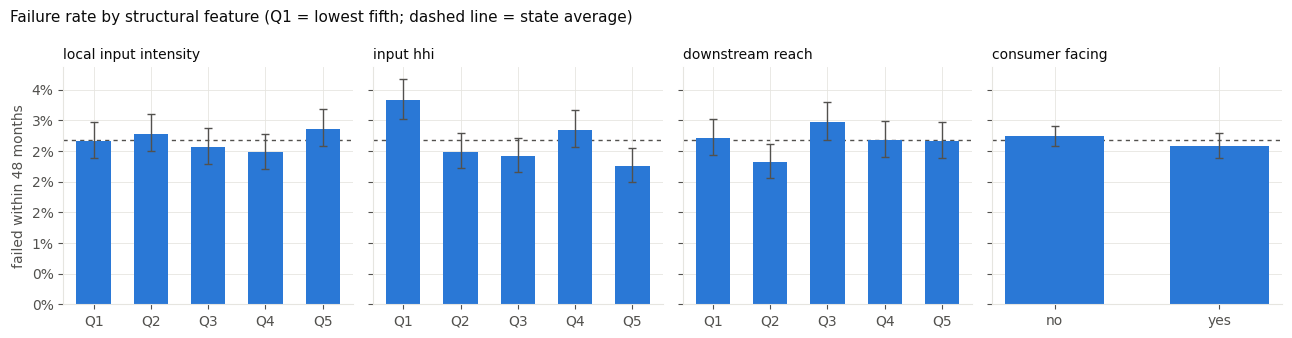

local_input_intensity  Q1: 2.7%  Q2: 2.8%  Q3: 2.6%  Q4: 2.5%  Q5: 2.9%
input_hhi              Q1: 3.3%  Q2: 2.5%  Q3: 2.4%  Q4: 2.8%  Q5: 2.3%
downstream_reach       Q1: 2.7%  Q2: 2.3%  Q3: 3.0%  Q4: 2.7%  Q5: 2.7%
consumer_facing        no: 2.7%  yes: 2.6%


In [8]:
import matplotlib.pyplot as plt

INK, INK2, GRID, BLUE, ORANGE = "#0b0b0b", "#52514e", "#e6e5e0", "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

def by_group(d, col, q=5):
    x = d[[col, "failed"]].dropna()
    if x[col].nunique() <= 2:
        g = x[col].astype(int).map({0: "no", 1: "yes"})
    else:
        g = pd.qcut(x[col].rank(method="first"), q, labels=[f"Q{i}" for i in range(1, q + 1)])
    t = x.groupby(g, observed=True).failed.agg(["sum", "size"])
    t["rate"] = t["sum"] / t["size"]
    t[["lo", "hi"]] = [wilson(int(s), int(n)) for s, n in zip(t["sum"], t["size"])]
    return t

fig, axes = plt.subplots(1, len(STRUCT_FEATURES), figsize=(13, 3.4), sharey=True)
quintile_tables = {}
for ax, col in zip(axes, STRUCT_FEATURES):
    t = by_group(elig, col)
    quintile_tables[col] = t
    xs = np.arange(len(t))
    ax.bar(xs, t.rate, width=0.6, color=BLUE, zorder=2)
    ax.errorbar(xs, t.rate, yerr=[t.rate - t.lo, t.hi - t.rate], fmt="none",
                ecolor=INK2, elinewidth=1, capsize=3, zorder=3)
    ax.axhline(elig.failed.mean(), color=INK2, linewidth=1, linestyle=(0, (3, 3)), zorder=1)
    ax.set_xticks(xs, [str(i) for i in t.index])
    ax.set_title(col.replace("_", " "), fontsize=10, loc="left")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel(f"failed within {HORIZON_MONTHS} months")
fig.suptitle("Failure rate by structural feature (Q1 = lowest fifth; dashed line = state average)",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
plt.show()

for col, t in quintile_tables.items():
    print(f"{col:<22} " + "  ".join(f"{i}: {r:.1%}" for i, r in zip(t.index, t.rate)))

# 6. The real test: train outside San Francisco, test inside it

Quintile charts can be fooled by anything that travels with an industry—loan size, loan length,
how new the business is, the year it borrowed. So we fit four models that differ only in what
they are allowed to know, and score each on San Francisco loans none of them saw:

| Model | Knows | Question it answers |
|---|---|---|
| **M0** | loan amount, term, business age, franchise, approval year | The baseline. A lender already knows all of this |
| **M1** | M0 + the graph's structural features | **Does what our graph sees about a business predict failure?** |
| **M2** | M0 + the industry's own past failure rate | How much does industry matter at all? |
| **M3** | M0 + both | What we will actually use |

**The score is AUC**: pick one loan that failed and one that did not; AUC is how often the model
ranks the failed one as riskier. 0.5 is a coin, 1.0 is perfect. We report each model's AUC with a
bootstrap interval, and—the number that matters—**how much each model adds over M0**.

Two details that keep this honest. The industry failure rate in M2 and M3 is computed **only from
training loans** and, for the training loans themselves, from other folds of them, so no loan
ever sees its own outcome. And the coefficients in the last table use **standard errors clustered
by industry**, because every loan in an industry shares the same structural values—ignoring that
would make weak effects look certain.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import KFold

def mom_strength(y, n, mean):
    """Prior pseudo-count for beta-binomial shrinkage, by method of moments.
    Larger = groups look alike, so trust the prior more."""
    keep = n >= 20
    y, n = y[keep], n[keep]
    if len(n) < 3 or mean <= 0 or mean >= 1:
        return 200.0
    p, w = y / n, n / n.sum()
    var_obs = float(np.sum(w * (p - mean) ** 2))
    var_noise = float(np.sum(w * mean * (1 - mean) / n))
    tau2 = max(var_obs - var_noise, 1e-7)
    return float(np.clip(mean * (1 - mean) / tau2 - 1, 5, 5000))

def industry_rates(d):
    """naics4 rate shrunk toward its sector, sector shrunk toward the state."""
    code = d.naics.astype("string")
    d = d.assign(naics4=code.str[:4].where(code.str.len() >= 4), naics2=code.str[:2])
    p0 = d.failed.mean()
    s2 = d.groupby("naics2").failed.agg(["sum", "size"])
    k2 = mom_strength(s2["sum"].values, s2["size"].values, p0)
    s2["p"] = (s2["sum"] + k2 * p0) / (s2["size"] + k2)
    s4 = d.groupby(["naics4", "naics2"]).failed.agg(["sum", "size"]).reset_index()
    s4["prior"] = s4.naics2.map(s2.p).fillna(p0)
    k4 = mom_strength(s4["sum"].values, s4["size"].values, p0)
    s4["p"] = (s4["sum"] + k4 * s4.prior) / (s4["size"] + k4)
    return {"p0": p0, "k2": k2, "k4": k4, "naics2": s2, "naics4": s4.set_index("naics4")}

def lookup_rate(naics, R):
    n = pd.Series(naics, dtype="string")
    p = n.str[:4].map(R["naics4"].p)
    p = p.fillna(n.str[:2].map(R["naics2"].p))
    return p.fillna(R["p0"]).astype(float).values

def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

def base_design(d):
    X = pd.get_dummies(pd.DataFrame({
            "fy":   "FY" + d.approval_fy.astype("Int64").astype(str),
            "term": pd.cut(d.term_months, [-1, 60, 84, 120, 240, 10_000],
                           labels=["<=5y", "5-7y", "7-10y", "10-20y", ">20y"]).astype(str),
            "age":  d.business_age.astype(str)}), drop_first=False, dtype=float)
    X["log_amount"] = np.log1p(d.gross_approval.fillna(d.gross_approval.median())).values
    X["franchised"] = d.franchised.astype(float).values
    return X

def struct_design(d):
    X = d[STRUCT_FEATURES].astype(float).copy()
    X["no_bea_match"] = d.bea_code.isna().astype(float).values
    return X

class Standardizer:
    def fit(self, X):
        self.mu = X.mean(); self.sd = X.std().replace(0, 1).fillna(1); self.med = X.median()
        return self
    def __call__(self, X):
        return ((X.fillna(self.med) - self.mu) / self.sd).fillna(0)

train = elig[~elig.sf].reset_index(drop=True)
test  = elig[elig.sf].reset_index(drop=True)
print(f"Train: {len(train):,} loans outside San Francisco, {int(train.failed.sum()):,} failed")
print(f"Test : {len(test):,} San Francisco loans, {int(test.failed.sum()):,} failed")
if test.failed.sum() < 30:
    print("  WARNING - fewer than 30 failures in the test set. The intervals below will be wide;")
    print("  read the statewide cross-validation line as well, which has far more failures.")

# Industry rate: cross-fitted on train, fit-on-all-train for test.
train["ind_rate"] = np.nan
for tr_idx, va_idx in KFold(5, shuffle=True, random_state=7).split(train):
    R = industry_rates(train.iloc[tr_idx])
    train.loc[va_idx, "ind_rate"] = lookup_rate(train.naics.iloc[va_idx], R)
test["ind_rate"] = lookup_rate(test.naics, industry_rates(train))

def build(d, which, cols=None):
    parts = [base_design(d)]
    if which in ("M1", "M3"):
        parts.append(struct_design(d))
    if which in ("M2", "M3"):
        parts.append(pd.DataFrame({"industry_logit": logit(d.ind_rate.values)}, index=d.index))
    X = pd.concat(parts, axis=1)
    return X if cols is None else X.reindex(columns=cols, fill_value=0.0)

MODELS, PRED = {}, {}
for m in ("M0", "M1", "M2", "M3"):
    Xtr = build(train, m)
    std = Standardizer().fit(Xtr)
    Xte = build(test, m, cols=Xtr.columns)
    clf = LogisticRegression(C=1.0, max_iter=5000).fit(std(Xtr), train.failed)
    MODELS[m] = (clf, std, list(Xtr.columns))
    PRED[m] = clf.predict_proba(std(Xte))[:, 1]

def paired_bootstrap(y, preds, n_boot=500, seed=11):
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    point = {m: roc_auc_score(y, p) for m, p in preds.items()}
    draws = {m: [] for m in preds}
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        for m, p in preds.items():
            draws[m].append(roc_auc_score(y[idx], p[idx]))
    draws = {m: np.array(v) for m, v in draws.items()}
    return point, draws

if test.failed.nunique() < 2:
    raise RuntimeError("The San Francisco test set has no failures (or only failures). Lower "
                       "HORIZON_MONTHS or check the SBA download.")
auc, draws = paired_bootstrap(test.failed.values, PRED)
labels = {"M0": "loan terms only", "M1": "+ graph structure", "M2": "+ industry failure rate",
          "M3": "+ both"}
print(f"\nOut-of-area AUC on {len(test):,} San Francisco loans (95% bootstrap interval)")
for m in PRED:
    lo, hi = np.percentile(draws[m], [2.5, 97.5])
    line = f"  {m}  {labels[m]:<24} {auc[m]:.3f}  [{lo:.3f}-{hi:.3f}]"
    if m != "M0":
        d = draws[m] - draws["M0"]
        dlo, dhi = np.percentile(d, [2.5, 97.5])
        line += f"   adds {auc[m] - auc['M0']:+.3f} [{dlo:+.3f} to {dhi:+.3f}]"
    print(line)

# A second opinion with many more failures: 5-fold CV across the whole state. The industry rate
# is cross-fitted inside each training fold too, so no loan's own outcome reaches its prediction.
def crossfit_rates(d, k=3, seed=5):
    out = np.full(len(d), np.nan)
    for a, b in KFold(k, shuffle=True, random_state=seed).split(d):
        out[b] = lookup_rate(d.naics.iloc[b], industry_rates(d.iloc[a]))
    return out

cv_auc = {}
for m in ("M0", "M1", "M3"):
    oof = np.zeros(len(elig))
    e = elig.reset_index(drop=True)
    for tr_idx, va_idx in KFold(5, shuffle=True, random_state=3).split(e):
        tr, va = e.iloc[tr_idx].copy(), e.iloc[va_idx].copy()
        if m == "M3":
            tr["ind_rate"] = crossfit_rates(tr)
            va["ind_rate"] = lookup_rate(va.naics, industry_rates(tr))
        Xtr = build(tr, m); std = Standardizer().fit(Xtr)
        clf = LogisticRegression(C=1.0, max_iter=5000).fit(std(Xtr), tr.failed)
        oof[va_idx] = clf.predict_proba(std(build(va, m, cols=Xtr.columns)))[:, 1]
    cv_auc[m] = roc_auc_score(e.failed, oof)
print(f"\nStatewide 5-fold CV AUC ({int(elig.failed.sum()):,} failures): "
      + "   ".join(f"{m} {v:.3f}" for m, v in cv_auc.items()))

def verdict(m):
    d = draws[m] - draws["M0"]
    lo, hi = np.percentile(d, [2.5, 97.5])
    if lo > 0.005:
        return "adds real, out-of-area predictive signal"
    if hi < 0.005:
        return "adds nothing you could defend"
    return "is inconclusive - the interval straddles zero"

print(f"\nREAD THIS: graph structure {verdict('M1')}; industry failure history {verdict('M2')}.")
result("auc_m0", f"{auc['M0']:.3f}", "loan terms only, San Francisco holdout")
result("auc_m1", f"{auc['M1']:.3f}", f"+ graph structural features; {verdict('M1')}")
result("auc_m2", f"{auc['M2']:.3f}", f"+ industry failure rate; {verdict('M2')}")
result("auc_m3", f"{auc['M3']:.3f}", "+ both (used for the corridor)")
result("holdout", f"{len(test):,} SF loans, {int(test.failed.sum())} failed",
       f"trained on {len(train):,} CA loans outside San Francisco")

Train: 57,157 loans outside San Francisco, 1,536 failed
Test : 1,490 San Francisco loans, 34 failed

Out-of-area AUC on 1,490 San Francisco loans (95% bootstrap interval)
  M0  loan terms only          0.700  [0.615-0.783]
  M1  + graph structure        0.695  [0.612-0.778]   adds -0.005 [-0.018 to +0.007]
  M2  + industry failure rate  0.704  [0.623-0.784]   adds +0.003 [-0.020 to +0.031]
  M3  + both                   0.700  [0.617-0.777]   adds -0.001 [-0.025 to +0.028]

Statewide 5-fold CV AUC (1,570 failures): M0 0.781   M1 0.782   M3 0.791

READ THIS: graph structure is inconclusive - the interval straddles zero; industry failure history is inconclusive - the interval straddles zero.


## Which structural features carry the signal, and in which direction

Odds ratios per one standard deviation of each feature, from M1 refit on the training loans,
with standard errors clustered by industry. An odds ratio of 1.20 means a business one standard
deviation further along that feature has 20% higher odds of failing, holding loan terms fixed.
**If the interval contains 1.00, the direction is not established.**

In [10]:
def cluster_logit(X, y, groups, ridge=1e-6, iters=50):
    """Logistic regression by Newton's method with cluster-robust (sandwich) standard errors.
    Written out rather than imported so it runs on any runtime."""
    X = np.column_stack([np.ones(len(X)), np.asarray(X, float)])
    y = np.asarray(y, float)
    beta = np.zeros(X.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X @ beta))
        H = X.T @ (X * (p * (1 - p))[:, None]) + ridge * np.eye(X.shape[1])
        step_ = np.linalg.solve(H, X.T @ (y - p))
        beta += step_
        if np.max(np.abs(step_)) < 1e-8:
            break
    p = 1 / (1 + np.exp(-X @ beta))
    Hinv = np.linalg.pinv(X.T @ (X * (p * (1 - p))[:, None]))
    scores = X * (y - p)[:, None]
    g = pd.Series(groups).factorize()[0]
    S = np.zeros((g.max() + 1, X.shape[1]))
    np.add.at(S, g, scores)
    G = g.max() + 1
    V = Hinv @ (S.T @ S) @ Hinv * G / max(G - 1, 1)
    return beta[1:], np.sqrt(np.clip(np.diag(V)[1:], 0, None)), G

Xtr = build(train, "M1")
Xtr = Xtr.loc[:, Xtr.std() > 0]
# Drop one dummy per categorical so the intercept is identified.
for prefix in ("fy_", "term_", "age_"):
    cols = [c for c in Xtr.columns if c.startswith(prefix)]
    if cols:
        Xtr = Xtr.drop(columns=cols[0])
std1 = Standardizer().fit(Xtr)
coef, se, n_clusters = cluster_logit(std1(Xtr).values, train.failed.values,
                                     train.bea_code.fillna("none").values)
cdf = pd.DataFrame({"coef": coef, "se": se}, index=Xtr.columns)
or_table = pd.DataFrame({
    "odds_ratio_per_sd": np.exp(cdf.coef),
    "ci_low": np.exp(cdf.coef - 1.96 * cdf.se),
    "ci_high": np.exp(cdf.coef + 1.96 * cdf.se),
}).loc[[c for c in STRUCT_FEATURES if c in cdf.index]]
or_table["direction"] = np.where(or_table.ci_low > 1, "more failure",
                         np.where(or_table.ci_high < 1, "less failure", "not established"))
print(f"Clustered by {n_clusters} BEA industries\n")
print(or_table.to_string(float_format=lambda v: f"{v:.2f}"))
for f_, r in or_table.iterrows():
    result(f"or_{f_}", f"{r.odds_ratio_per_sd:.2f} [{r.ci_low:.2f}-{r.ci_high:.2f}]",
           f"odds ratio per SD, clustered by industry: {r.direction}")

print("\nCalibration on the San Francisco holdout (M3): predicted vs observed, by fifth of risk")
cal = pd.DataFrame({"pred": PRED["M3"], "obs": test.failed.values})
cal["fifth"] = pd.qcut(cal.pred.rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
print(cal.groupby("fifth", observed=True).agg(predicted=("pred", "mean"), observed=("obs", "mean"),
      loans=("obs", "size")).to_string(float_format=lambda v: f"{v:.2%}"))

Clustered by 64 BEA industries

                       odds_ratio_per_sd  ci_low  ci_high        direction
local_input_intensity               0.98    0.90     1.07  not established
input_hhi                           0.90    0.82     0.99     less failure
downstream_reach                    0.95    0.85     1.07  not established
consumer_facing                     0.94    0.83     1.07  not established

Calibration on the San Francisco holdout (M3): predicted vs observed, by fifth of risk
       predicted  observed  loans
fifth                            
Q1         0.06%     0.34%    298
Q2         1.12%     1.34%    298
Q3         2.20%     1.68%    298
Q4         3.40%     3.69%    298
Q5         7.31%     4.36%    298


# 7. The hub question, answered with outcomes

The README warns that if your agent always funds the most connected business, you have built a
centrality calculator. Here is the evidence for or against that warning. For every BEA industry
with enough loans, compare **how much of a hub it is** (how many industries buy from it) with
**how often its businesses actually failed**.

If the correlation is near zero or negative, being a hub tells you about the **consequence** of a
closure and nothing about its **likelihood**. That is precisely why the grant decision needs both
numbers, and it is the sentence that answers a judge who asks "when does your agent not fund the
biggest hub?"

In [11]:
from scipy.stats import spearmanr

hub = (elig.dropna(subset=["bea_code"])
           .groupby("bea_code")
           .agg(loans=("failed", "size"), failed=("failed", "sum"),
                downstream_reach=("downstream_reach", "first"),
                local_input_intensity=("local_input_intensity", "first")))
hub = hub[hub.loans >= 100].dropna(subset=["downstream_reach", "local_input_intensity"])
hub["rate"] = hub.failed / hub.loans
rho, pval = spearmanr(hub.downstream_reach, hub.rate)
rho2, pval2 = spearmanr(hub.local_input_intensity, hub.rate)
print(f"Industries with at least 100 eligible loans: {len(hub)}")
print(f"  hub-ness (downstream reach) vs failure rate : Spearman rho = {rho:+.2f} (p = {pval:.2f})")
print(f"  input dependence vs failure rate            : Spearman rho = {rho2:+.2f} (p = {pval2:.2f})")
print("\nMost and least hub-like industries:")
print(hub.sort_values("downstream_reach", ascending=False)
         .iloc[np.r_[0:5, -5:0]][["downstream_reach", "loans", "rate"]]
         .to_string(float_format=lambda v: f"{v:.3f}"))
hub_msg = ("hubs are NOT more likely to fail - fund on consequence x likelihood, not reach alone"
           if rho <= 0.1 or pval > 0.05 else
           "hub industries DO fail more often in this data - reach and risk point the same way")
print(f"\nREAD THIS: {hub_msg}")
result("hub_test", f"rho {rho:+.2f} (p={pval:.2f}, {len(hub)} industries)", hub_msg)

Industries with at least 100 eligible loans: 47
  hub-ness (downstream reach) vs failure rate : Spearman rho = -0.14 (p = 0.33)
  input dependence vs failure rate            : Spearman rho = -0.05 (p = 0.74)

Most and least hub-like industries:
          downstream_reach  loans  rate
bea_code                               
5412OP              65.000   4579 0.032
HS                  58.000   1201 0.017
521CI               56.000    123 0.049
561                 51.000   1784 0.030
524                 43.000    545 0.013
452                  0.000    102 0.059
4A0                  0.000   5092 0.030
713                  0.000   1012 0.036
623                  0.000    547 0.009
624                  0.000    610 0.021

READ THIS: hubs are NOT more likely to fail - fund on consequence x likelihood, not reach alone


# 8. Write the failure probability for every industry

This is the table the agent uses. For each four-digit industry: how many California loans, how
many failed, the raw rate, and **the rate we actually use**—the raw rate pulled toward its sector's
rate in proportion to how little data the industry has. An industry with three loans and one
failure does not get a 33% failure probability; it gets something close to its sector. An
industry with four thousand loans keeps almost exactly its own rate. The strength of the pull is
estimated from the data, not chosen by us.

These rates use **all** eligible California loans (the validation above held San Francisco out;
for the corridor we want every loan we have). The interval is a 90% credible interval: the
agent should quote it, because "between 3% and 9%" is more honest than "6%".

In [ ]:
from scipy.stats import beta as beta_dist

R_ALL = industry_rates(elig)
rows = []
s4, s2 = R_ALL["naics4"], R_ALL["naics2"]
for code, r in s4.iterrows():
    a = r["sum"] + R_ALL["k4"] * r.prior
    b = r["size"] - r["sum"] + R_ALL["k4"] * (1 - r.prior)
    rows.append(("naics4", code, int(r["size"]), int(r["sum"]), r["sum"] / r["size"], r.prior, r.p,
                 beta_dist.ppf(0.05, a, b), beta_dist.ppf(0.95, a, b)))
for code, r in s2.iterrows():
    a = r["sum"] + R_ALL["k2"] * R_ALL["p0"]
    b = r["size"] - r["sum"] + R_ALL["k2"] * (1 - R_ALL["p0"])
    rows.append(("naics2", code, int(r["size"]), int(r["sum"]), r["sum"] / r["size"], R_ALL["p0"], r.p,
                 beta_dist.ppf(0.05, a, b), beta_dist.ppf(0.95, a, b)))
_n, _k = len(elig), int(elig.failed.sum())
rows.append(("state", STATE, _n, _k, _k / _n, np.nan, _k / _n,
             beta_dist.ppf(0.05, _k + 1, _n - _k + 1), beta_dist.ppf(0.95, _k + 1, _n - _k + 1)))
industry_failure_rates = pd.DataFrame(rows, columns=[
    "level", "code", "n_loans", "n_failed", "raw_rate", "prior_rate", "p_fail", "p_fail_lo90", "p_fail_hi90"])
industry_failure_rates["horizon_months"] = HORIZON_MONTHS
industry_failure_rates["basis"] = (f"CA SBA 7(a) loans to incorporated businesses, FY{int(elig.approval_fy.min())}-"
                                   f"FY{int(elig.approval_fy.max())}, as of {SBA_ASOF:%Y-%m-%d}")
print(f"Shrinkage strength: sector k = {R_ALL['k2']:.0f} pseudo-loans, industry k = {R_ALL['k4']:.0f}")
print("\nThe pull in action - smallest and largest industries in the data:")
_v = industry_failure_rates[industry_failure_rates.level == "naics4"].sort_values("n_loans")
print(pd.concat([_v.head(4), _v.tail(4)])[["code", "n_loans", "n_failed", "raw_rate", "prior_rate",
      "p_fail", "p_fail_lo90", "p_fail_hi90"]].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

# One export for SQL, agents and the local source review. Never reconstruct priors
# from the old hand-entered sba_industry_failure_rates.csv.
from pathlib import Path
export_dir = Path("data")
export_dir.mkdir(exist_ok=True)
job_source = elig.assign(naics4=elig.naics.astype("string").str[:4],
                         naics2=elig.naics.astype("string").str[:2])
job_source["jobs_supported"] = pd.to_numeric(job_source.jobs_supported, errors="coerce").where(lambda x:x>=0)
job_medians = {level: job_source.groupby(level).jobs_supported.median()
               for level in ("naics4","naics2")}
industry_failure_rates["median_jobs_supported"] = [
    job_source.jobs_supported.median() if r.level=="state" else job_medians[r.level].get(r.code,np.nan)
    for r in industry_failure_rates.itertuples()]
industry_failure_rates.to_csv(export_dir / "industry_failure_rates.csv", index=False)
# Republish the same canonical table with the computed loan-cohort job proxy.
load_table(industry_failure_rates,"industry_failure_rates","Canonical horizon-specific charge-off priors and industry SBA job proxies; not business employment")
# Jobs are an industry SBA loan-cohort proxy, not measured jobs at these businesses.
print("Canonical rates exported to", export_dir / "industry_failure_rates.csv")


# 9. Raw likelihood × reach baseline, before the reviewed shortlist

`p_fail` is an industry SBA loan charge-off prior, not a verified business closure
probability. `reach_2hop` is unique modeled supply exposure. Their product is a
baseline diagnostic and can still favor the largest hub. A flat grant multiplier
scales that baseline without changing rank; it does not measure what the money buys.

Section 10b replaces the consequence recommendation with weighted two-hop
exposure and a separate 5–25 destination cascade band. It tests depths one through
eight and compares industry concentration. Deeper impact is reported only where
the graph actually gains destinations. No industry is excluded from the distance
comparison. Applicant evidence and a separate essential-access/direct-relief review
are required before allocating grants.


In [ ]:
# Refresh source availability; setup remains an explicit action.
HAVE = {t: table_exists(t) for t in needed + optional}
if not (HAVE["businesses"] and HAVE["supplies"]):
    raise RuntimeError("Load the corridor source tables first. This validation does not download and execute a remote loader or provision a paid reservation automatically.")

try:
    CORRIDOR = str(bq(f"SELECT ANY_VALUE(corridor) AS c FROM `{DS}.businesses`").c.iloc[0])
except Exception:                                                       # noqa: BLE001
    pass

FOOTFALL_OK = HAVE["employer_blocks"] and HAVE["draws_footfall_from"]

def graph_ddl(name):
    """The DDL from Section 13 of the load notebook. Element tables are DATASET.TABLE, unbackticked;
    REFERENCES takes the bare table name. Footfall is included only if its tables exist."""
    nodes = [f"""    {DATASET}.businesses
      KEY (business_id)
      LABEL Business PROPERTIES (business_id, name, naics4, zip, latitude, longitude)"""]
    edges = [f"""    {DATASET}.supplies
      KEY (edge_id)
      SOURCE KEY (supplier_id) REFERENCES businesses (business_id)
      DESTINATION KEY (buyer_id) REFERENCES businesses (business_id)
      LABEL Supplies PROPERTIES (intensity, metres)"""]
    if FOOTFALL_OK:
        nodes.append(f"""    {DATASET}.employer_blocks
      KEY (block_id)
      LABEL Employer PROPERTIES (block_id, jobs)""")
        edges.append(f"""    {DATASET}.draws_footfall_from
      KEY (edge_id)
      SOURCE KEY (block_id) REFERENCES employer_blocks (block_id)
      DESTINATION KEY (business_id) REFERENCES businesses (business_id)
      LABEL DrawsFootfall PROPERTIES (worker_share, metres)""")
    return (f"CREATE OR REPLACE PROPERTY GRAPH {name}\n  NODE TABLES (\n" + ",\n".join(nodes)
            + "\n  )\n  EDGE TABLES (\n" + ",\n".join(edges) + "\n  )\n")

def ensure_graph():
    """Use the canonical graph if it answers. Explicit notebook setup may rebuild
    LocalEconomy over the current source tables; no second graph is introduced."""
    global GRAPH
    try:
        n_nodes = int(bq(f"GRAPH {GRAPH} MATCH (b:Business) RETURN COUNT(*) AS n").n.iloc[0])
        print(f"Using the team's graph {GRAPH} ({n_nodes:,} Business nodes). Not modifying it.")
        return True
    except Exception as exc:                                            # noqa: BLE001
        msg = str(exc)
        if "reservation" in msg.lower():
            print("Graph queries need the Enterprise reservation from Section 1b of the load notebook.")
            print("Run that cell (or bash scripts/load.sh), wait a minute, and re-run this one.")
            return False
        own = f"{DATASET}.LocalEconomy"
        print(f"{GRAPH} did not answer ({msg.splitlines()[0][:140]}).")
        print(f"Building the canonical {own} over the source tables; run the reviewed SQL after section 10 to add verified loan edges.")
        GRAPH = own
    client.query(graph_ddl(GRAPH)).result()
    print(f"Created {GRAPH}.")
    return True

TRAVERSAL = {}
def traverse(name, gql, sql_fallback):
    """Run the GQL. Two spellings of the same aggregation are tried: the implicit grouping the load
    notebook verified on BigQuery (its Section 13), then an explicit GROUP BY, which BigQuery's GQL
    reference also documents. If both fail, say so loudly and use plain SQL, so the validation still
    finishes. The agent must use the GQL path - this fallback only protects the validation numbers."""
    if GRAPH_OK:
        for spelling, q in (("GQL", gql), ("GQL (explicit GROUP BY)", gql.rstrip() + "\nGROUP BY business_id\n")):
            try:
                df = bq(q)
                TRAVERSAL[name] = spelling
                return df
            except Exception as exc:                                    # noqa: BLE001
                print(f"  {spelling} for {name} failed: {str(exc).splitlines()[0][:160]}")
    TRAVERSAL[name] = "SQL fallback"
    print(f"  {name}: using the SQL fallback - fix the graph before the demo")
    return bq(sql_fallback)

with step("graph traversals"):
    GRAPH_OK = ensure_graph()

    reach = traverse("reach_2hop", f"""
GRAPH {GRAPH}
MATCH (seed:Business)-[:Supplies]->{{1,2}}(exposed:Business)
WHERE seed.business_id != exposed.business_id
RETURN seed.business_id AS business_id,
       COUNT(DISTINCT exposed.business_id) AS reach_2hop
""", f"""
WITH hop AS (
  SELECT supplier_id AS root, buyer_id AS reached FROM `{DS}.supplies`
  UNION ALL
  SELECT a.supplier_id, b.buyer_id FROM `{DS}.supplies` a
  JOIN `{DS}.supplies` b ON b.supplier_id = a.buyer_id
)
SELECT root AS business_id, COUNT(DISTINCT reached) AS reach_2hop
FROM hop WHERE reached != root GROUP BY root
""")

    direct = traverse("direct_buyers", f"""
GRAPH {GRAPH}
MATCH (seed:Business)-[:Supplies]->{{1,1}}(exposed:Business)
RETURN seed.business_id AS business_id,
       COUNT(DISTINCT exposed.business_id) AS direct_buyers
""", f"""
SELECT supplier_id AS business_id, COUNT(DISTINCT buyer_id) AS direct_buyers
FROM `{DS}.supplies` GROUP BY supplier_id
""")

    inbound = traverse("local_suppliers", f"""
GRAPH {GRAPH}
MATCH (sup:Business)-[e:Supplies]->(b:Business)
RETURN b.business_id AS business_id,
       COUNT(DISTINCT sup.business_id) AS local_suppliers,
       SUM(e.intensity) AS supplier_intensity
""", f"""
SELECT buyer_id AS business_id, COUNT(DISTINCT supplier_id) AS local_suppliers,
       SUM(intensity) AS supplier_intensity
FROM `{DS}.supplies` GROUP BY buyer_id
""")

    if FOOTFALL_OK:
        foot = traverse("footfall", f"""
GRAPH {GRAPH}
MATCH (blk:Employer)-[f:DrawsFootfall]->(b:Business)
RETURN b.business_id AS business_id,
       SUM(f.worker_share) AS footfall_workers,
       COUNT(DISTINCT blk.block_id) AS footfall_blocks
""", f"""
SELECT business_id, SUM(worker_share) AS footfall_workers, COUNT(DISTINCT block_id) AS footfall_blocks
FROM `{DS}.draws_footfall_from` GROUP BY business_id
""")
    else:
        foot = pd.DataFrame(columns=["business_id", "footfall_workers", "footfall_blocks"])

print("\nHow each measure was computed:", TRAVERSAL)

biz = bq(f"SELECT business_id, name, address, naics, naics4 FROM `{DS}.businesses`")
for frame in (reach, direct, inbound, foot):
    frame["business_id"] = frame.business_id.astype(str)
biz["business_id"] = biz.business_id.astype(str)
fz = (biz.merge(reach, on="business_id", how="left")
         .merge(direct, on="business_id", how="left")
         .merge(inbound, on="business_id", how="left")
         .merge(foot, on="business_id", how="left"))
for c in ("reach_2hop", "direct_buyers", "local_suppliers", "footfall_blocks"):
    fz[c] = pd.to_numeric(fz[c], errors="coerce").fillna(0).astype(int)
for c in ("supplier_intensity", "footfall_workers"):
    fz[c] = pd.to_numeric(fz[c], errors="coerce").fillna(0.0).astype(float)

# Likelihood: naics4, else sector, else state - and record which one we had to use.
r4 = industry_failure_rates[industry_failure_rates.level == "naics4"].set_index("code")
r2 = industry_failure_rates[industry_failure_rates.level == "naics2"].set_index("code")
rs = industry_failure_rates[industry_failure_rates.level == "state"].iloc[0]
code4 = fz.naics4.astype("string").str[:4]
code2 = fz.naics4.astype("string").str[:2]
fz["p_fail_level"] = np.where(code4.isin(r4.index), "naics4", np.where(code2.isin(r2.index), "naics2", "state"))
for col in ("p_fail", "p_fail_lo90", "p_fail_hi90", "n_loans"):
    fz[col] = np.where(fz.p_fail_level == "naics4", code4.map(r4[col]),
               np.where(fz.p_fail_level == "naics2", code2.map(r2[col]), rs[col])).astype(float)
fz = fz.rename(columns={"n_loans": "rate_basis_loans"})
fz["rate_basis_loans"] = fz.rate_basis_loans.astype(int)

fz["expected_exposed"]   = fz.p_fail * fz.reach_2hop
fz["protected_by_grant"] = fz.expected_exposed * GRANT_RELATIVE_RISK_REDUCTION
fz = add_structure(fz, naics_col="naics")

has = fz.reach_2hop > 0
reach_cut = float(fz.loc[has, "reach_2hop"].median()) if has.any() else 0.0
p_cut = float(fz.p_fail.median())
fz["quadrant"] = np.select(
    [has & (fz.reach_2hop >= reach_cut) & (fz.p_fail >= p_cut),
     has & (fz.reach_2hop >= reach_cut) & (fz.p_fail < p_cut),
     (fz.p_fail >= p_cut)],
    ["high reach, higher industry loan prior",
     "high reach, lower industry loan prior",
     "lower reach, higher industry loan prior"],
    default="lower reach, lower industry loan prior")
fz["p_fail_pctile"] = fz.p_fail.rank(pct=True)

print(f"\nCorridor businesses              : {len(fz):,}")
print(f"  with anything 2 hops downstream: {int(has.sum()):,}")
print(f"  failure probability from       : " + ", ".join(f"{k} {v}" for k, v in fz.p_fail_level.value_counts().items()))
print(f"  thresholds: reach_2hop >= {reach_cut:.0f}, p_fail >= {p_cut:.1%} (corridor medians)")
print("\n" + fz.quadrant.value_counts().to_string())

print("\nRaw reach baseline only — not the grant recommendation:")
cols = ["name", "naics4", "p_fail", "p_fail_lo90", "p_fail_hi90", "reach_2hop", "expected_exposed", "quadrant"]
print(fz.sort_values("expected_exposed", ascending=False)[cols].head(10).to_string(
    index=False, float_format=lambda v: f"{v:.3f}"))

print("\nMost connected businesses - and why the most connected is not automatically the pick:")
print(fz.sort_values("reach_2hop", ascending=False)[cols].head(5).to_string(
    index=False, float_format=lambda v: f"{v:.3f}"))
rho_c, p_c = spearmanr(fz.loc[has, "reach_2hop"], fz.loc[has, "p_fail"]) if has.sum() > 3 else (np.nan, np.nan)
print(f"\nIn this corridor, reach vs failure probability: Spearman rho = {rho_c:+.2f}")

# The assumption, stress-tested: does the top of the list change if the grant does more or less?
# protected_by_grant is linear in the assumption, so the ORDER cannot change - only the size of the
# claim does. That is worth saying: the ranking is robust to it; the dollar-for-impact figure is not.
top = fz.sort_values("expected_exposed", ascending=False).head(1)
if len(top) and top.expected_exposed.iloc[0] > 0:
    t0 = top.iloc[0]
    print(f"\nWhat the assumption does to the top case ({t0['name']}):")
    for rr in (0.10, 0.25, 0.50):
        print(f"  grant cuts failure risk by {rr:.0%}: protects {t0.expected_exposed * rr:.2f} businesses "
              f"in expectation")
    print("  This raw baseline ranking does not move under a flat multiplier; section 10b tests a debt bridge.")
    print("  of the claim does. Quote the range, not one number.")
    result("raw_baseline_top_case", t0["name"], f"p_fail {t0.p_fail:.1%} [{t0.p_fail_lo90:.1%}-{t0.p_fail_hi90:.1%}], "
           f"reach_2hop {int(t0.reach_2hop)}, expected exposed {t0.expected_exposed:.2f}")
result("corridor_reach_vs_risk", f"rho {rho_c:+.2f}", "Spearman, businesses with a 2-hop cascade")
result("traversal", ", ".join(f"{k}: {v}" for k, v in TRAVERSAL.items()), "how each graph measure was computed")

## Raw-reach diagnostic for the deck

This scatterplot separates an industry loan prior from modeled reach. High reach
does not establish high risk, and the top-right is not automatically a grant winner.
Show the negative holdout result alongside this plot. The reviewed shortlist and
its selection bias are reported in section 10b.


In [ ]:
# Businesses in the same industry share a failure probability, so several can sit on one point.
# One marker per point, sized by how many businesses it holds, so nothing hides behind anything.
pts = (fz[has].sort_values("expected_exposed", ascending=False)
          .groupby(["p_fail", "reach_2hop"], as_index=False)
          .agg(n=("business_id", "size"), first=("name", "first"),
               expected_exposed=("expected_exposed", "first"), quadrant=("quadrant", "first")))
pts["label"] = np.where(pts.n > 1, pts["first"].astype(str).str[:24] + " +" + (pts.n - 1).astype(str),
                        pts["first"].astype(str).str[:28])
fig, ax = plt.subplots(figsize=(8.5, 5.4))
hot = pts.quadrant.str.startswith("high reach, higher")
for mask, colour, lab, z in ((~hot, BLUE, "other businesses with a cascade", 2),
                             (hot, ORANGE, "higher prior and high reach", 3)):
    ax.scatter(pts.p_fail[mask], pts.reach_2hop[mask], s=34 + 22 * (pts.n[mask] - 1), color=colour,
               alpha=0.85, edgecolor="white", linewidth=1.5, label=lab, zorder=z)
ax.axvline(p_cut, color=INK2, linewidth=1, linestyle=(0, (3, 3)), zorder=1)
ax.axhline(reach_cut, color=INK2, linewidth=1, linestyle=(0, (3, 3)), zorder=1)
for _, r in pts.sort_values("expected_exposed", ascending=False).head(5).iterrows():
    ax.annotate(r.label, (r.p_fail, r.reach_2hop), xytext=(7, 3), textcoords="offset points",
                fontsize=8.5, color=INK)
ax.text(0.99, 0.98, "high reach / higher industry prior: review evidence", transform=ax.transAxes, ha="right", va="top",
        fontsize=9, color=INK2)
ax.text(0.01, 0.98, "high reach / lower industry prior: not an automatic award", transform=ax.transAxes, ha="left", va="top",
        fontsize=9, color=INK2)
ax.set_ylim(0, max(float(pts.reach_2hop.max()) * 1.15, 1))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel(f"industry loan charge-off prior within {HORIZON_MONTHS} months (SBA loan cohort)")
ax.set_ylabel("businesses within 2 supply hops (GQL)")
ax.set_title(f"{CORRIDOR}: raw reach baseline — not a grant recommendation",
             loc="left", fontsize=11, pad=26)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9,
          markerscale=0.9, handletextpad=0.3)
fig.tight_layout()
plt.show()

# 10. Ground truth in your own corridor

The statewide test says whether the *kind* of business we call fragile tends to fail. This
section asks the sharper, smaller question: **of the businesses in this corridor that actually
borrowed from the SBA, which failed, and what did our model think of them?**

We re-run the load notebook's name match against **both** SBA files, so loans from FY2010 onward
count—older loans are the ones whose outcome is known. Then we check every match by street
number, because the load notebook matches on name alone and two businesses can share a name.

**Read the counts before the conclusions.** This will be a handful of loans. A handful is a set
of stories, not a statistic, and it should be presented that way: "here is a business that
really failed, and here is where our model placed it."

In [ ]:
CORP_SUFFIX = re.compile(r"\b(inc|llc|l\.l\.c|corp|corporation|ltd|limited|lp|llp|company|co)\b\.?",
                         re.IGNORECASE)
def norm_name(s):
    s = str(s).upper()
    s = re.sub(r"[^A-Z0-9 ]", " ", s)
    s = CORP_SUFFIX.sub(" ", s)
    return re.sub(r"\s+", " ", s).strip()

def street_key(s):
    """('1020', 'MARKET') from '1020 Market St', for checking a name match against an address."""
    m = re.match(r"\s*(\d+)[A-Z\-]*\s+(?:[NSEW]\s+)?([A-Z0-9]+)", str(s).upper())
    return (m.group(1), m.group(2)) if m else (None, None)

if sba_sf_named is not None:
    corridor_biz = bq(f"SELECT business_id, name, legal_name, address, naics4 FROM `{DS}.businesses`")
    corridor_biz["business_id"] = corridor_biz.business_id.astype(str)
    keys = pd.concat([corridor_biz.assign(_k=corridor_biz.name.map(norm_name)),
                      corridor_biz.assign(_k=corridor_biz.legal_name.map(norm_name))])
    keys = keys[keys._k.str.len() > 3].drop_duplicates(["business_id", "_k"])
    s = sba_sf_named.assign(_k=sba_sf_named.BorrName.map(norm_name))
    s = s[s._k.str.len() > 3]
    m = keys.merge(s, on="_k", how="inner")
    # the same loan can match via both the trade name and the legal name
    m = m.drop_duplicates(["business_id", "BankName", "ApprovalDate", "GrossApproval"])
    bk = m.address.map(street_key)
    sk = m.BorrStreet.map(street_key)
    m["address_check"] = np.where(
        [a[0] is None or b[0] is None for a, b in zip(bk, sk)], "no street number",
        np.where([a == b for a, b in zip(bk, sk)], "same street address",
        np.where([a[1] == b[1] for a, b in zip(bk, sk)], "same street, different number",
                 "different street - likely a different location or business")))
    months = (pd.to_datetime(m._chargeoff) - pd.to_datetime(m._approval)).dt.days / 30.4375
    observed = pd.to_datetime(m._approval) <= SBA_ASOF - pd.DateOffset(months=HORIZON_MONTHS)
    corridor_loans = pd.DataFrame({
        "business_id":      m.business_id.values,
        "corridor":         CORRIDOR,
        "registry_name":    m["name"].values,
        "registry_address": m.address.values,
        "sba_street":       m.BorrStreet.astype("string").str.title().values,
        "address_check":    m.address_check.values,
        "bank_name":        m.BankName.values,
        "gross_approval":   num(m.GrossApproval).values,
        "approval_date":    pd.to_datetime(m._approval).values,
        "source_file":      m.source_file.values,
        "loan_status":      m._status.values,
        "term_months":      num(m.TermInMonths).values,
        "jobs_supported":   num(m.JobsSupported).values,
        "charged_off":      (m._status == "CHGOFF").values,
        "chargeoff_date":   pd.to_datetime(m._chargeoff).values,
        "months_to_chargeoff": months.where(m._status == "CHGOFF").values,
        "observed_full_horizon": observed.values,
    })
    load_table(corridor_loans, "corridor_loan_outcomes",
               "REAL loans, OUR match. SBA 7(a) FY2010-present loans matched to corridor businesses by "
               "normalized name within SF ZIPs, with a street-address check. Matching is ours; outcomes are SBA's.")
elif table_exists("corridor_loan_outcomes"):
    corridor_loans = bq(f"SELECT * FROM `{DS}.corridor_loan_outcomes`")
    if len(corridor_loans) and corridor_loans.corridor.iloc[0] != CORRIDOR:
        print(f"corridor_loan_outcomes was built for {corridor_loans.corridor.iloc[0]}, not {CORRIDOR}.")
        print("Set REFRESH_SBA = True and re-run to rebuild it for this corridor.")
        corridor_loans = corridor_loans.iloc[0:0]
else:
    corridor_loans = (bq(f"SELECT * FROM `{DS}.borrowed_from`") if HAVE["borrowed_from"]
                      else pd.DataFrame(columns=["business_id", "charged_off"]))
    print("Using the load notebook's borrowed_from (FY2020+ only, unchecked). Set REFRESH_SBA = True")
    print("to rebuild the extended, address-checked match.")

n_load = int(bq(f"SELECT COUNT(*) AS n FROM `{DS}.borrowed_from`").n.iloc[0]) if HAVE["borrowed_from"] else 0
print(f"\nLoans matched by the load notebook (FY2020+, name only): {n_load}")
print(f"Loans matched here (FY2010+, with address check)       : {len(corridor_loans)}")
if "address_check" in corridor_loans:
    print(corridor_loans.address_check.value_counts().to_string())
print(f"Charged off: {int(corridor_loans.charged_off.astype(bool).sum()) if len(corridor_loans) else 0}")

if len(corridor_loans):
    cl = corridor_loans.copy()
    cl["business_id"] = cl.business_id.astype(str)
    cs = cl.merge(fz[["business_id", "name", "naics4", "p_fail", "p_fail_pctile", "reach_2hop", "quadrant"]],
                  on="business_id", how="left")
    show = [c for c in ["name", "naics4", "approval_date", "loan_status", "months_to_chargeoff",
                        "address_check", "p_fail", "p_fail_pctile", "reach_2hop", "quadrant"] if c in cs]
    print("\nEvery matched loan, failures first:")
    print(cs.sort_values("charged_off", ascending=False)[show].to_string(
        index=False, float_format=lambda v: f"{v:.2f}"))

    unverified = "different street - likely a different location or business"
    status_col = "loan_status" if "loan_status" in cs else None
    never_lent = (cs[status_col].astype("string").str.upper().str.replace(r"\s+", "", regex=True)
                  .isin(["CANCLD", "COMMIT"])) if status_col else pd.Series(False, index=cs.index)
    if never_lent.any():
        print(f"\nSet aside {int(never_lent.sum())} cancelled or undisbursed loan(s): the money never went out.")
    trusted = cs[(cs.get("address_check", pd.Series("", index=cs.index)) == "same street address") & ~never_lent]
    print(f"Strict same-street-address matches: {len(trusted)}. Missing street numbers are not verified.")
    failed_cases = trusted[trusted.charged_off.astype(bool)]
    repaid_cases = trusted[~trusted.charged_off.astype(bool)]
    n_street = int((cs.get("address_check", pd.Series("", index=cs.index)) == unverified).sum())
    if n_street:
        print(f"Set aside {n_street} match(es) whose SBA street differs from the registry.")
    if len(failed_cases):
        print(f"\nFailed businesses sat at the {failed_cases.p_fail_pctile.mean():.0%} percentile of corridor "
              f"failure probability on average (n = {len(failed_cases)}); businesses that repaid or are "
              f"still paying sat at {repaid_cases.p_fail_pctile.mean():.0%} (n = {len(repaid_cases)}).")
        print("With numbers this small, present these as cases, not as accuracy.")
        print(f"\nAll {failed_cases.business_id.nunique()} charged-off business(es) still appear as OPEN in the "
              "City registry - the load")
        print("notebook only kept open locations. A charge-off is a failed loan, not always a closed door.")
        result("corridor_failures", f"{len(failed_cases)} of {len(trusted)} matched loans charged off",
               f"failed sat at {failed_cases.p_fail_pctile.mean():.0%} percentile of predicted risk vs "
               f"{repaid_cases.p_fail_pctile.mean():.0%} for the rest" if len(repaid_cases)
               else "no repaid comparison")
    else:
        result("corridor_failures", f"0 of {len(trusted)} matched loans charged off",
               "no in-corridor failure to compare against; the statewide test is the evidence")
else:
    result("corridor_failures", "no SBA loans matched in this corridor",
           "the statewide test is the evidence; say so in the demo")

## 10b. Reviewed consequences, depth, diversity and grant sensitivity

This section supersedes the raw reach ranking as the cascade recommendation. A 5–25 band is an explicit policy choice; it does not prove a bakery or any named business should win. All industries remain in distance sensitivity. Missing evidence remains unknown. The local map uses the separately labeled registry/BEA model; this section uses the current BigQuery graph inputs.


In [ ]:
# Run from a checkout containing the updated tools/resilience_analysis.py.
# Full graph inputs are queried, not guessed from degrees or NAICS counts.
import json
from tools.resilience_analysis import (CorridorGraph, naics_detail, rank_consequences,
                                      industry_variety, grant_scenario)
node_frame = bq(f"SELECT TO_JSON_STRING(b) AS record FROM `{DS}.businesses` b")
review_nodes = []
for payload in node_frame.record:
    n = json.loads(payload)
    n["business_id"] = str(n["business_id"])
    n.update(naics_detail(n.get("naics", n.get("naics4", ""))))
    review_nodes.append(n)
review_edges = json.loads(bq(f"SELECT supplier_id,buyer_id,intensity,metres FROM `{DS}.supplies`").to_json(orient="records"))
review_graph = CorridorGraph(review_nodes, review_edges)

# Verify quantified GQL traversal through eight hops against table-based BFS.
try:
    gql_depth = bq(f"""
    GRAPH {GRAPH}
    MATCH ANY SHORTEST (s:Business)-[edges:Supplies]->{{1,8}}(d:Business)
    WHERE s.business_id != d.business_id
    RETURN s.business_id AS business_id,d.business_id AS destination_id,
           ARRAY_LENGTH(edges) AS shortest_hop
    """)
    TRAVERSAL["depth_1_to_8"]="GQL ANY SHORTEST; compared with table-based BFS"
    for n in review_nodes:
        expected={r["business_id"]:r["hop"] for r in review_graph.trace(n["business_id"],8)["endpoints"]}
        actual={str(r.destination_id):int(r.shortest_hop) for r in gql_depth[gql_depth.business_id.astype(str)==n["business_id"]].itertuples()}
        if actual!=expected:
            raise AssertionError("GQL and source-table reach differ; rebuild LocalEconomy over the current source tables")
except AssertionError:
    raise
except Exception as exc:
    TRAVERSAL["depth_1_to_8"]="Table-based BFS only; GQL not verified"
    print("Eight-hop GQL verification unavailable:",str(exc).splitlines()[0])

# 1–8 hops: unique destinations, shortest explanation paths, cycle-safe counts.
profiles = [review_graph.trace(n["business_id"], 8) for n in review_nodes]
depth_review = pd.DataFrame([
    {"hops":h, "median_reach":np.median([r["profile"][h-1]["cumulative_businesses"] for r in profiles]),
     "max_reach":max(r["profile"][h-1]["cumulative_businesses"] for r in profiles),
     "roots_with_new_destinations":sum(r["profile"][h-1]["new_businesses"]>0 for r in profiles)}
    for h in range(1,9)])
print("Depth sensitivity — not a forecast of closures:")
print(depth_review.to_string(index=False))

# Grant effects require CURRENT applicant debt inputs. Historical approval/term is
# not an observed current payment. Populate only from verified applicant evidence.
VERIFIED_MONTHLY_DEBT = {}  # business_id -> current monthly debt service
reviewed = pd.DataFrame(rank_consequences(review_graph, industry_failure_rates.to_dict("records"),
                                          grant=8000, debt_by_id=VERIFIED_MONTHLY_DEBT))
show = ["name","reach_2hop","old_expected_exposed","new_expected_exposure",
        "rank_before_decay","rank_after_decay","cascade_case"]
print("Old raw-reach baseline (all businesses):")
print(reviewed.sort_values("old_expected_exposed",ascending=False)[show].head(10).to_string(index=False))
shortlist = reviewed[reviewed.cascade_case].sort_values("new_expected_exposure",ascending=False)
print("New weighted two-hop cascade shortlist (5–25 distinct destinations):")
print(shortlist[show].head(10).to_string(index=False))
print("Outside the band -> separate direct-relief/essential-access review, not automatic rejection.")
print("No winner is hardcoded; report honestly if the same business still leads.")
if len(shortlist):
    top_case = shortlist.iloc[0]
    result("reviewed_top_case",top_case["name"],
           f"weighted exposure {top_case.new_expected_exposure:.6f}; no grant award certified")
print("Industry variety — source and cascade shortlist:")
print(industry_variety(review_nodes))
print(industry_variety(review_nodes, set(shortlist.business_id)))
for rr in (0.10,0.25,0.50):
    scenarios = [dict(business_id=r.business_id, **grant_scenario(r.p_fail,8000,
                 VERIFIED_MONTHLY_DEBT.get(r.business_id),max_reduction=rr))
                 for r in reviewed.itertuples()]
    print(f"$8,000, max reduction {rr:.0%}:",scenarios[:5])
print("Debt-bridge scenario results stay unknown where current debt inputs are absent.")

# Replace the consequence columns in the published output. Keep raw reach as a
# named baseline rather than relabeling the old hub score as a recommendation.
metrics=["reach_2hop","weighted_before_decay","weighted_after_decay","cascade_case",
         "new_expected_exposure","rank_before_decay","rank_after_decay"]
fz=fz.drop(columns=[c for c in metrics if c in fz]).merge(reviewed[["business_id"]+metrics],on="business_id",how="left",validate="one_to_one")
load_table(depth_review,"graph_depth_sensitivity","Unique downstream destinations at depths 1–8; modeled supply graph")
load_table(reviewed.drop(columns=["grant_scenario"]),"cascade_review","All-business raw vs weighted exposure, separate 5–25 cascade band; not grant approvals")

# Held-out confusion matrix: rate fit outside SF, applied to SF. Threshold fixed
# at 3% for this diagnostic; no full-data priors leaking the test outcomes.
y_true=test.failed.to_numpy(dtype=int)
y_hat=(lookup_rate(test.naics,industry_rates(train))>=0.03).astype(int)
confusion=pd.DataFrame([{"threshold":0.03,"tp":int(((y_true==1)&(y_hat==1)).sum()),
    "fp":int(((y_true==0)&(y_hat==1)).sum()),"tn":int(((y_true==0)&(y_hat==0)).sum()),
    "fn":int(((y_true==1)&(y_hat==0)).sum()),"cohort":"SF holdout; rates fit outside SF"}])
print("Held-out charge-off confusion matrix (not business closures):")
print(confusion.to_string(index=False))
load_table(confusion,"chargeoff_confusion_matrix","SF holdout, 3% threshold, rate fit outside SF")

# Equity audit: nearest matched workplace block's tract is only a geographic
# proxy. It does not count unique residents served or justify jobs-saved claims.
if FOOTFALL_OK and table_exists("tract_demographics"):
    equity=bq(fr"""
    WITH nearest AS (
      SELECT f.business_id,ARRAY_AGG(e.tract IGNORE NULLS ORDER BY f.metres LIMIT 1)[SAFE_OFFSET(0)] AS tract
      FROM `{DS}.draws_footfall_from` f JOIN `{DS}.employer_blocks` e USING(block_id)
      GROUP BY f.business_id
    )
    SELECT n.business_id,t.poverty_rate,t.no_vehicle_rate
    FROM nearest n LEFT JOIN `{DS}.tract_demographics` t
      ON REGEXP_EXTRACT(CAST(t.geo_id AS STRING),r'(\d{{11}})$')=CAST(n.tract AS STRING)
    """)
    equity["business_id"]=equity.business_id.astype(str)
    equity=reviewed[["business_id","industry_type","cascade_case"]].merge(equity,on="business_id",how="left",validate="one_to_one")
    print("Equity coverage (nearest workplace-tract proxy):",equity.poverty_rate.notna().sum(),"of",len(equity))
    print(equity.groupby("cascade_case")[["poverty_rate","no_vehicle_rate"]].agg(["count","mean"]))
    load_table(equity,"cascade_equity_audit","Nearest workplace-tract proxy; unweighted means; not resident reach")
else:
    print("Equity audit unavailable: missing local ACS/footfall source tables; no proxy invented.")


# 11. Write it all down

`business_fragility` is the table the agent's tool should join to its cascade query. The block
printed below is for the story lane: every number in it came from a cell above, and each line is
phrased to be said out loud.

In [ ]:
out_cols = ["business_id", "name", "naics", "naics4", "bea_code", "p_fail", "p_fail_lo90", "p_fail_hi90",
            "p_fail_level", "rate_basis_loans", "p_fail_pctile", "reach_2hop", "direct_buyers",
            "local_suppliers", "supplier_intensity", "footfall_workers", "footfall_blocks",
            "local_input_intensity", "input_hhi", "downstream_reach", "consumer_facing",
            "expected_exposed", "protected_by_grant", "quadrant"]
out_cols += [c for c in ("weighted_before_decay", "weighted_after_decay", "cascade_case",
                        "new_expected_exposure", "rank_before_decay", "rank_after_decay") if c in fz]
business_fragility = fz[out_cols].copy().rename(columns={
    "expected_exposed":"baseline_raw_expected_exposed",
    "protected_by_grant":"baseline_flat_multiplier_exposure"})
business_fragility["horizon_months"] = HORIZON_MONTHS
business_fragility["grant_risk_reduction_assumed"] = GRANT_RELATIVE_RISK_REDUCTION
load_table(business_fragility, "business_fragility",
           f"p_fail is REAL OUTCOMES (industry charge-off rate within {HORIZON_MONTHS} months, CA SBA 7(a)). "
           f"reach_2hop is MODELED (GQL over the supply graph). baseline_flat_multiplier_exposure applies an ASSUMED "
           f"{GRANT_RELATIVE_RISK_REDUCTION:.0%} relative cut in failure risk.")

summary = pd.DataFrame([(k, v, d) for k, (v, d) in RESULTS.items()], columns=["metric", "value", "detail"])
summary["corridor"] = CORRIDOR
summary["horizon_months"] = HORIZON_MONTHS
load_table(summary, "validation_summary", "Headline numbers from c3_02_chargeoff_validation.ipynb")

def R(k):
    return RESULTS.get(k, ("n/a", ""))

print("=" * 96)
print(f"CHARGE-OFF VALIDATION - {CORRIDOR} - numbers for the deck and the memo")
print("=" * 96)
print(f"Ground truth : {R('base_rate')[1]}.")
print(f"               Base rate {R('base_rate')[0]}; San Francisco {R('base_rate_sf')[0]}.")
print(f"Test         : {R('holdout')[1]}; scored on {R('holdout')[0]}.")
print(f"               AUC  loan terms only {R('auc_m0')[0]}  |  + graph structure {R('auc_m1')[0]}"
      f"  |  + industry history {R('auc_m2')[0]}  |  both {R('auc_m3')[0]}")
print(f"               Graph structure {R('auc_m1')[1].split('; ')[-1]}.")
print(f"               Industry failure history {R('auc_m2')[1].split('; ')[-1]}.")
for f_ in STRUCT_FEATURES:
    if f"or_{f_}" in RESULTS:
        print(f"               {f_:<22} odds ratio per SD {R('or_' + f_)[0]} -> {R('or_' + f_)[1].split(': ')[-1]}")
print(f"Hub test     : {R('hub_test')[0]} -> {R('hub_test')[1]}.")
print(f"Corridor     : {R('corridor_failures')[0]}; {R('corridor_failures')[1]}.")
if "raw_baseline_top_case" in RESULTS:
    print(f"Raw baseline : {R('raw_baseline_top_case')[0]} - not the recommendation.")
if "reviewed_top_case" in RESULTS:
    print(f"Reviewed case: {R('reviewed_top_case')[0]} - {R('reviewed_top_case')[1]}.")
print(f"Assumption   : a grant cuts failure risk by {GRANT_RELATIVE_RISK_REDUCTION:.0%} (not in any data; "
      f"flat baseline only; debt bridge sensitivity is in section 10b).")
print(f"Traversal    : {R('traversal')[0]}")
print("=" * 96)

# What this can and cannot tell you

Say these before a judge does. Each one is a sentence, and together they are most of your
"rigor and judgment" score.

* **SBA borrowers are not every business.** They qualified for a bank loan with a federal
  guarantee. Failure rates here are rates *among businesses like that*, and those outcomes do not establish risk for excluded sole proprietors or unbanked businesses.
* **A charge-off is a failed loan, not always a closed business,** and a business can close
  without defaulting. It is the best outcome measure available in public data, and it is still
  a proxy.
* **The failure probability is industry-level.** Two restaurants on the same block get the same
  number. That is honest about what the data supports; a business's own finances would sharpen
  it, and nothing public has them.
* **The structural features are industry-level too,** because the edge generator only ever sees a
  business as its industry. A weak result for them is partly a statement about the generator,
  which is a reason to improve it, and a good thing to say.
* **Pandemic cohorts are in the data.** FY2020–FY2021 loans failed, and were forgiven, for reasons
  that have nothing to do with a corridor's structure. Approval year is in every model.
* **The corridor match is by name.** We check street numbers, and the table says which matches are
  verified. Unverified ones should not carry a slide.
* **What a grant does is assumed, not measured.** `GRANT_RELATIVE_RISK_REDUCTION` is a stated
  assumption for the flat baseline. The debt-bridge sensitivity varies only with verified current inputs; it remains unknown where those inputs are missing.

# Appendix: diagnostic summary

In [ ]:
print("=" * 70)
print("C3_02 CHARGE-OFF VALIDATION - DIAGNOSTIC SUMMARY")
print("=" * 70)
print(f"Project / dataset : {PROJECT_ID} / {DATASET}")
print(f"Corridor          : {CORRIDOR}")
print(f"Graph             : {GRAPH} ({'ok' if globals().get('GRAPH_OK') else 'not reached'})")
print(f"SBA as-of         : {SBA_ASOF:%Y-%m-%d}; files: {', '.join(SBA_FILES)}")
print(f"Horizon           : {HORIZON_MONTHS} months")
print(f"Loans             : {len(loans):,} CA; eligible {len(elig):,}; train {len(train):,}; test {len(test):,}")
print(f"Traversal engine  : {TRAVERSAL}")
print("-" * 70)
for name, secs in STEP_TIMES.items():
    print(f"  {name:<36} {secs:>7.1f}s")
print(f"  {'TOTAL WALL CLOCK':<36} {time.time() - NOTEBOOK_START:>7.1f}s")
print("=" * 70)